# Prepare the MLCQ Dataset for Binary Code Smell Detection

This notebook prepares `MLCQCodeSmellSamples.xlsx` or `MLCQCodeSmellSamples.csv` for model training.

It does everything inside the notebook. There are no imported project scripts.

The raw MLCQ sample file has review metadata, not a direct `code` column. The actual Java snippet is reconstructed from:

- `repository`
- `commit_hash`
- `path`
- `start_line`
- `end_line`

The final training task is:

```text
Input:  Java code snippet + target smell
Output: absent / present
```

Severity mapping:

```text
none                   -> absent
minor, major, critical -> present
```

## 1. Configuration

Update `INPUT_FILE` to match your Kaggle dataset path.

For example, after adding the MLCQ file as a Kaggle dataset, the path may look like:

```python
INPUT_FILE = "/kaggle/input/datasets/fatemakotb02/mlcqcodesmellsamples/MLCQCodeSmellSamples.xlsx"
```

Keep `FETCH_CODE = True` when Kaggle internet is enabled. If internet is disabled, the notebook will not be able to retrieve Java snippets from GitHub.

In [1]:
from pathlib import Path

# Change this path in Kaggle if needed.
INPUT_FILE = Path("/kaggle/input/datasets/fatemakotb02/mlcqcodesmellsamples/MLCQCodeSmellSamples.xlsx")

OUTPUT_DIR = Path("/kaggle/working/outputs/data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
TEST_SIZE = 0.15
VAL_SIZE = 0.15

# Set to a small number such as 100 while testing the notebook quickly.
# Set to None for the full dataset.
MAX_SAMPLES_TO_FETCH = None

# Required because the raw MLCQ file does not contain the Java code text.
FETCH_CODE = True

print("Input file:", INPUT_FILE)
print("Output dir:", OUTPUT_DIR)

Input file: /kaggle/input/datasets/fatemakotb02/mlcqcodesmellsamples/MLCQCodeSmellSamples.xlsx
Output dir: /kaggle/working/outputs/data


## 2. Imports

In [2]:
import json
import random
import re
import time
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.model_selection import GroupShuffleSplit

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kwargs):
        return x

# Show up to 100 columns when displaying a pandas DataFrame.
# This is useful because the MLCQ file has many metadata columns,
# and pandas may otherwise hide some columns with "...".
pd.set_option("display.max_columns", 100)

# Show up to 120 characters per cell when displaying text columns.
# This makes columns like code_name, repository, path, and link easier to inspect
# without printing extremely long values in full.
pd.set_option("display.max_colwidth", 120)

random.seed(SEED)
np.random.seed(SEED)


## 3. Fixed MLCQ Schema

These are the exact columns used by the MLCQ samples file.

In [3]:
REQUIRED_COLUMNS = [
    "id",
    "reviewer_id",
    "sample_id",
    "smell",
    "severity",
    "review_timestamp",
    "type",
    "code_name",
    "repository",
    "commit_hash",
    "path",
    "start_line",
    "end_line",
    "link",
    "is_from_industry_relevant_project",
]

SEVERITY_TO_LABEL = {
    "none": "absent",
    "minor": "present",
    "major": "present",
    "critical": "present",
}

LABEL_TO_ID = {
    "absent": 0,
    "present": 1,
}

## 4. Load the Raw MLCQ File

The official CSV uses semicolon separators, while the XLSX file can be read directly.

In [4]:
def load_mlcq_file(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    suffix = path.suffix.lower()

    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)

    if suffix == ".csv":
        # Official MLCQ CSV is semicolon-separated. sep=None is a useful fallback.
        try:
            return pd.read_csv(path, sep=";", encoding="utf-8")
        except Exception:
            return pd.read_csv(path, sep=None, engine="python", encoding="utf-8")

    raise ValueError(f"Unsupported file type: {suffix}")

raw_df = load_mlcq_file(INPUT_FILE)
print(raw_df.shape)
raw_df.head()

(14739, 15)


,id,reviewer_id,sample_id,smell,severity,review_timestamp,type,code_name,repository,commit_hash,path,start_line,end_line,link,is_from_industry_relevant_project
0,526,6,5771277,feature envy,none,2019-03-27 10:34:53.041496,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0
1,527,6,5771277,long method,none,2019-03-27 10:34:53.042443,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0
2,528,6,5786929,blob,critical,2019-03-27 10:37:38.107923,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0
3,529,6,5786929,data class,critical,2019-03-27 10:37:38.109068,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0
4,530,6,5788107,feature envy,none,2019-03-27 10:37:49.627100,function,org.apache.tika.parser.ocr.TesseractOCRConfig#getImageMagickPath,git@github.com:apache/tika.git,4131c6e30f2e0eb1feb85e0f7576531d4e830468,/tika-parsers/src/main/java/org/apache/tika/parser/ocr/TesseractOCRConfig.java,531,534,https://github.com/apache/tika/blob/4131c6e30f2e0eb1feb85e0f7576531d4e830468/tika-parsers/src/main/java/org/apache/t...,1.0


## 5. Validate Columns

In [5]:
def validate_raw_schema(df: pd.DataFrame) -> None:
    missing = [col for col in REQUIRED_COLUMNS if col not in df.columns]
    extra = [col for col in df.columns if col not in REQUIRED_COLUMNS]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    print("Schema OK")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))

    if extra:
        print("Extra columns found:", extra)

validate_raw_schema(raw_df)

Schema OK
Rows: 14739
Columns: 15


## 6. Clean Metadata and Create Review-Level Binary Labels

At this point each row is still one human review.

In [6]:
def clean_review_rows(df: pd.DataFrame) -> pd.DataFrame:
    clean = df.copy()

    # Keep only the expected columns and use a stable order.
    clean = clean[REQUIRED_COLUMNS]

    # Normalize text columns.
    for col in ["smell", "severity", "type", "repository", "commit_hash", "path", "link", "code_name"]:
        clean[col] = clean[col].astype(str).str.strip()

    clean["smell"] = clean["smell"].str.lower()
    clean["severity"] = clean["severity"].str.lower()
    clean["type"] = clean["type"].str.lower()

    # Numeric cleanup.
    clean["id"] = pd.to_numeric(clean["id"], errors="coerce").astype("Int64")
    clean["reviewer_id"] = pd.to_numeric(clean["reviewer_id"], errors="coerce").astype("Int64")
    clean["sample_id"] = pd.to_numeric(clean["sample_id"], errors="coerce").astype("Int64")
    clean["start_line"] = pd.to_numeric(clean["start_line"], errors="coerce").astype("Int64")
    clean["end_line"] = pd.to_numeric(clean["end_line"], errors="coerce").astype("Int64")
    clean["is_from_industry_relevant_project"] = pd.to_numeric(
        clean["is_from_industry_relevant_project"], errors="coerce"
    ).astype("float64")

    # Parse timestamp, but do not use it as a model feature.
    clean["review_timestamp"] = pd.to_datetime(clean["review_timestamp"], errors="coerce")

    unknown_severities = sorted(set(clean["severity"].dropna()) - set(SEVERITY_TO_LABEL))
    if unknown_severities:
        raise ValueError(f"Unknown severity values: {unknown_severities}")

    clean["label"] = clean["severity"].map(SEVERITY_TO_LABEL)
    clean["label_id"] = clean["label"].map(LABEL_TO_ID).astype(int)
    clean["target_smell"] = clean["smell"]

    # Remove rows with critical missing values.
    critical_cols = [
        "id", "reviewer_id", "sample_id", "target_smell", "severity",
        "repository", "commit_hash", "path", "start_line", "end_line"
    ]
    clean = clean.dropna(subset=critical_cols).reset_index(drop=True)

    return clean

reviews_df = clean_review_rows(raw_df)
reviews_df.to_csv(OUTPUT_DIR / "mlcq_reviews_clean.csv", index=False)
print(reviews_df.shape)
reviews_df.head()

(14739, 18)


,id,reviewer_id,sample_id,smell,severity,review_timestamp,type,code_name,repository,commit_hash,path,start_line,end_line,link,is_from_industry_relevant_project,label,label_id,target_smell
0,526,6,5771277,feature envy,none,2019-03-27 10:34:53.041496,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0,absent,0,feature envy
1,527,6,5771277,long method,none,2019-03-27 10:34:53.042443,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0,absent,0,long method
2,528,6,5786929,blob,critical,2019-03-27 10:37:38.107923,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0,present,1,blob
3,529,6,5786929,data class,critical,2019-03-27 10:37:38.109068,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0,present,1,data class
4,530,6,5788107,feature envy,none,2019-03-27 10:37:49.627100,function,org.apache.tika.parser.ocr.TesseractOCRConfig#getImageMagickPath,git@github.com:apache/tika.git,4131c6e30f2e0eb1feb85e0f7576531d4e830468,/tika-parsers/src/main/java/org/apache/tika/parser/ocr/TesseractOCRConfig.java,531,534,https://github.com/apache/tika/blob/4131c6e30f2e0eb1feb85e0f7576531d4e830468/tika-parsers/src/main/java/org/apache/t...,1.0,absent,0,feature envy


## 7. Quick EDA on the Raw Reviews

In [7]:
print("Review rows:", len(reviews_df))
print("Unique code samples:", reviews_df["sample_id"].nunique())
print("Unique sample + smell pairs:", reviews_df[["sample_id", "target_smell"]].drop_duplicates().shape[0])
print("Reviewers:", reviews_df["reviewer_id"].nunique())

print("\nSeverity counts:")
display(reviews_df["severity"].value_counts().rename_axis("severity").reset_index(name="count"))

print("\nSmell counts:")
display(reviews_df["target_smell"].value_counts().rename_axis("target_smell").reset_index(name="count"))

print("\nSmell by severity:")
display(pd.crosstab(reviews_df["target_smell"], reviews_df["severity"]))

Review rows: 14739
Unique code samples: 4770
Unique sample + smell pairs: 9517
Reviewers: 26

Severity counts:


,severity,count
0,none,11448
1,minor,1787
2,major,1129
3,critical,375



Smell counts:


,target_smell,count
0,data class,4021
1,blob,4019
2,long method,3362
3,feature envy,3337



Smell by severity:


severity,critical,major,minor,none
target_smell,,,,
blob,127,312,535,3045
data class,146,401,510,2964
feature envy,24,142,288,2883
long method,78,274,454,2556


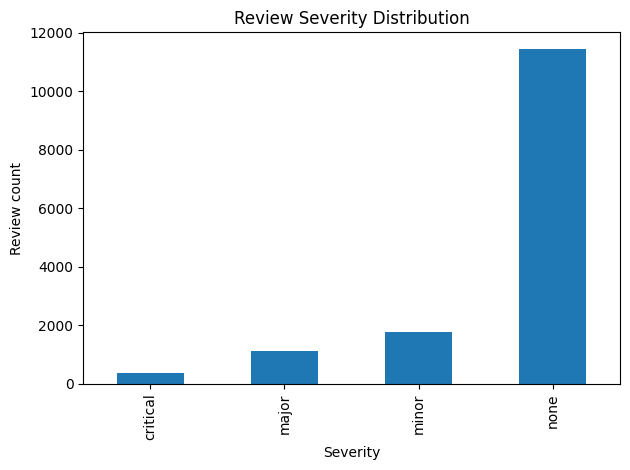

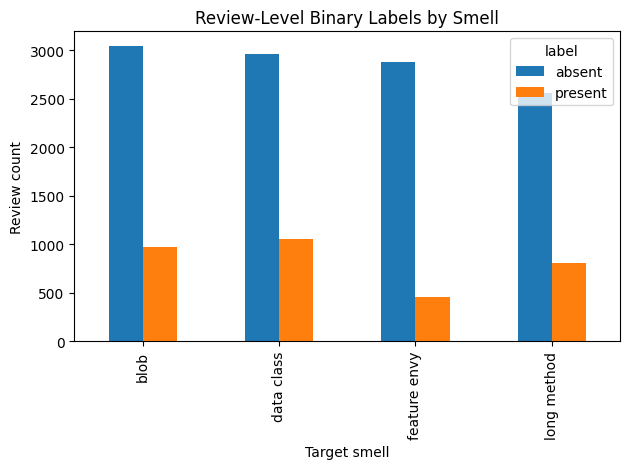

In [8]:
plot_dir = OUTPUT_DIR / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

severity_counts = reviews_df["severity"].value_counts().sort_index()
ax = severity_counts.plot(kind="bar", title="Review Severity Distribution")
ax.set_xlabel("Severity")
ax.set_ylabel("Review count")
plt.tight_layout()
plt.savefig(plot_dir / "review_severity_distribution.png", dpi=150)
plt.show()

smell_label_counts = pd.crosstab(reviews_df["target_smell"], reviews_df["label"])
ax = smell_label_counts.plot(kind="bar", title="Review-Level Binary Labels by Smell")
ax.set_xlabel("Target smell")
ax.set_ylabel("Review count")
plt.tight_layout()
plt.savefig(plot_dir / "review_binary_labels_by_smell.png", dpi=150)
plt.show()

## 8. Build GitHub Raw URLs

The MLCQ file provides GitHub metadata, not code text. This section converts each row into a raw GitHub file URL.

Example:

```text
git@github.com:apache/syncope.git
```

becomes:

```text
https://raw.githubusercontent.com/apache/syncope/<commit_hash>/<path>
```

In [9]:
def github_slug_from_repository(repository: str) -> str:
    repo = str(repository).strip()

    if repo.startswith("git@github.com:"):
        repo = repo.replace("git@github.com:", "", 1)
    elif repo.startswith("https://github.com/"):
        repo = repo.replace("https://github.com/", "", 1)
    elif repo.startswith("http://github.com/"):
        repo = repo.replace("http://github.com/", "", 1)

    if repo.endswith(".git"):
        repo = repo[:-4]

    return repo.strip("/")


def build_raw_github_url(repository: str, commit_hash: str, path: str) -> str:
    slug = github_slug_from_repository(repository)
    clean_path = str(path).strip().lstrip("/")
    return f"https://raw.githubusercontent.com/{slug}/{commit_hash}/{clean_path}"

reviews_df["raw_file_url"] = reviews_df.apply(
    lambda row: build_raw_github_url(row["repository"], row["commit_hash"], row["path"]),
    axis=1,
)

reviews_df[["repository", "commit_hash", "path", "start_line", "end_line", "raw_file_url"]].head(3)

,repository,commit_hash,path,start_line,end_line,raw_file_url
0,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://raw.githubusercontent.com/apache/syncope/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/...
1,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://raw.githubusercontent.com/apache/syncope/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/...
2,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://raw.githubusercontent.com/apache/tez/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/j...


## 9. Fetch Java Snippets from GitHub

This fetches each unique code sample once, then merges the snippet back onto all review rows.

If you are testing the notebook, set `MAX_SAMPLES_TO_FETCH = 100` in the configuration cell first.

In [10]:
def extract_lines(file_text: str, start_line: int, end_line: int) -> str:
    lines = file_text.splitlines()
    start_idx = int(start_line) - 1
    end_idx = int(end_line)

    if start_idx < 0 or end_idx < start_idx:
        return ""

    return "\n".join(lines[start_idx:end_idx]).strip()


def fetch_text(url: str, timeout: int = 30, retries: int = 3, sleep_seconds: float = 1.0) -> tuple[Optional[str], str]:
    last_error = ""

    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, timeout=timeout)
            if response.status_code == 200:
                return response.text, "ok"
            last_error = f"HTTP {response.status_code}"
        except Exception as exc:
            last_error = repr(exc)

        if attempt < retries:
            time.sleep(sleep_seconds)

    return None, last_error


def fetch_code_sample(row: pd.Series) -> dict:
    text, status = fetch_text(row["raw_file_url"])

    if text is None:
        return {
            "sample_id": row["sample_id"],
            "code": "",
            "fetch_status": status,
            "raw_file_url": row["raw_file_url"],
        }

    code = extract_lines(text, row["start_line"], row["end_line"])

    if not code:
        status = "empty_snippet"

    return {
        "sample_id": row["sample_id"],
        "code": code,
        "fetch_status": status,
        "raw_file_url": row["raw_file_url"],
    }

In [11]:
# One row per code sample. The same sample can have multiple smell reviews.
unique_samples = (
    reviews_df.sort_values(["sample_id", "id"])
    .drop_duplicates(subset=["sample_id"])
    [[
        "sample_id", "type", "code_name", "repository", "commit_hash", "path",
        "start_line", "end_line", "link", "raw_file_url"
    ]]
    .reset_index(drop=True)
)

if MAX_SAMPLES_TO_FETCH is not None:
    unique_samples_to_fetch = unique_samples.head(MAX_SAMPLES_TO_FETCH).copy()
else:
    unique_samples_to_fetch = unique_samples.copy()

selected_sample_ids = set(unique_samples_to_fetch["sample_id"].astype(int))

print("Unique samples:", len(unique_samples))
print("Samples to fetch now:", len(unique_samples_to_fetch))
unique_samples_to_fetch.head()

Unique samples: 4770
Samples to fetch now: 4770


,sample_id,type,code_name,repository,commit_hash,path,start_line,end_line,link,raw_file_url
0,3698323,class,com.amazon.ask.dispatcher.request.handler.impl.PlaybackNearlyFinishedRequestHandler,git@github.com:alexa/alexa-skills-kit-sdk-for-java.git,bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9,/ask-sdk-core/src/com/amazon/ask/dispatcher/request/handler/impl/PlaybackNearlyFinishedRequestHandler.java,26,59,https://github.com/alexa/alexa-skills-kit-sdk-for-java/blob/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-sdk-core/sr...,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
1,3698602,function,com.amazon.ask.request.mapper.impl.BaseRequestMapper.Builder#build,git@github.com:alexa/alexa-skills-kit-sdk-for-java.git,bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9,/ask-sdk-runtime/src/com/amazon/ask/request/mapper/impl/BaseRequestMapper.java,79,81,https://github.com/alexa/alexa-skills-kit-sdk-for-java/blob/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-sdk-runtime...,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
2,3698665,function,"com.amazon.ask.builder.impl.AbstractSkillBuilder#addExceptionHandler GenericExceptionHandler<Input, Output>",git@github.com:alexa/alexa-skills-kit-sdk-for-java.git,bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9,/ask-sdk-runtime/src/com/amazon/ask/builder/impl/AbstractSkillBuilder.java,91,94,https://github.com/alexa/alexa-skills-kit-sdk-for-java/blob/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-sdk-runtime...,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
3,3698860,function,com.alibaba.android.arouter.facade.model.RouteMeta#toString,git@github.com:alibaba/ARouter.git,93b328569bbdbf75e4aa87f0ecf48c69600591b2,/arouter-annotation/src/main/java/com/alibaba/android/arouter/facade/model/RouteMeta.java,200,213,https://github.com/alibaba/ARouter/blob/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/main/java/co...,https://raw.githubusercontent.com/alibaba/ARouter/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/ma...
4,3699227,function,com.alibaba.android.arouter.facade.enums.#getClassName,git@github.com:alibaba/ARouter.git,93b328569bbdbf75e4aa87f0ecf48c69600591b2,/arouter-annotation/src/main/java/com/alibaba/android/arouter/facade/enums/RouteType.java,32,34,https://github.com/alibaba/ARouter/blob/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/main/java/co...,https://raw.githubusercontent.com/alibaba/ARouter/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/ma...


In [12]:
cache_path = OUTPUT_DIR / "sample_code_cache.csv"

if cache_path.exists():
    code_cache = pd.read_csv(cache_path)
    print("Loaded existing cache:", code_cache.shape)
else:
    code_cache = pd.DataFrame(columns=["sample_id", "code", "fetch_status", "raw_file_url"])
    print("No existing cache found.")

# Only treat successfully fetched, non-empty snippets as cached.
# Failed fetches should be retried when the notebook is rerun.
valid_cache = code_cache[
    (code_cache["fetch_status"] == "ok") &
    (code_cache["code"].fillna("").str.len() > 0)
].copy()

cached_ok_ids = set(
    pd.to_numeric(valid_cache["sample_id"], errors="coerce")
    .dropna()
    .astype(int)
    .tolist()
)

needed_samples = unique_samples_to_fetch[
    ~unique_samples_to_fetch["sample_id"].astype(int).isin(cached_ok_ids)
].copy()

print("Successfully cached:", len(cached_ok_ids))
print("Need to fetch or retry:", len(needed_samples))

No existing cache found.
Successfully cached: 0
Need to fetch or retry: 4770


In [13]:
if FETCH_CODE and len(needed_samples) > 0:
    fetched_rows = []

    for _, row in tqdm(needed_samples.iterrows(), total=len(needed_samples), desc="Fetching code"):
        fetched_rows.append(fetch_code_sample(row))

    new_cache = pd.DataFrame(fetched_rows)
    code_cache = pd.concat([code_cache, new_cache], ignore_index=True)

    # Keep latest result per sample_id if the cell is re-run.
    code_cache = code_cache.drop_duplicates(subset=["sample_id"], keep="last")
    code_cache.to_csv(cache_path, index=False)

elif not FETCH_CODE:
    print("FETCH_CODE is False. Skipping GitHub retrieval.")
else:
    print("Nothing new to fetch.")

print(code_cache["fetch_status"].value_counts(dropna=False).head(20))
code_cache.head()

Fetching code:   0%|          | 0/4770 [00:00<?, ?it/s]

fetch_status
ok          4364
HTTP 404     406
Name: count, dtype: int64


,sample_id,code,fetch_status,raw_file_url
0,3698323,public interface PlaybackNearlyFinishedRequestHandler extends RequestHandler {\n\n /**\n * Returns true if th...,ok,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
1,3698602,"public GenericRequestMapper<Input, Output> build() {\n return new BaseRequestMapper<>(handlerChains);\n ...",ok,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
2,3698665,"public Self addExceptionHandler(GenericExceptionHandler<Input, Output> handler) {\n exceptionHandlers.add(han...",ok,https://raw.githubusercontent.com/alexa/alexa-skills-kit-sdk-for-java/bf1e9ccc50d1f3f8408f887f70197ee288fd4bd9/ask-s...
3,3698860,"@Override\n public String toString() {\n return ""RouteMeta{"" +\n ""type="" + type +\n ...",ok,https://raw.githubusercontent.com/alibaba/ARouter/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/ma...
4,3699227,public String getClassName() {\n return className;\n },ok,https://raw.githubusercontent.com/alibaba/ARouter/93b328569bbdbf75e4aa87f0ecf48c69600591b2/arouter-annotation/src/ma...


In [14]:
# Keep only the selected sample IDs.
# This makes MAX_SAMPLES_TO_FETCH behave predictably during testing.
reviews_selected = reviews_df[
    reviews_df["sample_id"].astype(int).isin(selected_sample_ids)
].copy()

# Make the cache safe before merging.
# If the cache accidentally contains multiple rows for the same sample_id,
# keep one row only. Prefer a successful non-empty fetch over a failed one.
code_cache["sample_id"] = pd.to_numeric(code_cache["sample_id"], errors="coerce").astype("Int64")
code_cache = code_cache.dropna(subset=["sample_id"]).copy()

code_cache["is_valid_cache"] = (
    (code_cache["fetch_status"] == "ok") &
    (code_cache["code"].fillna("").str.len() > 0)
)

code_cache = (
    code_cache
    .sort_values(["sample_id", "is_valid_cache"], ascending=[True, False])
    .drop_duplicates(subset=["sample_id"], keep="first")
    .drop(columns=["is_valid_cache"])
    .reset_index(drop=True)
)

# Save the cleaned cache so future notebook runs also use the deduplicated cache.
code_cache.to_csv(cache_path, index=False)

code_cache_selected = code_cache[
    code_cache["sample_id"].astype(int).isin(selected_sample_ids)
].copy()

reviews_with_code = reviews_selected.merge(
    code_cache_selected[["sample_id", "code", "fetch_status"]],
    on="sample_id",
    how="left",
)

reviews_with_code["code"] = reviews_with_code["code"].fillna("")
reviews_with_code["fetch_status"] = reviews_with_code["fetch_status"].fillna("not_fetched")

fetch_failures = reviews_with_code.loc[
    (reviews_with_code["fetch_status"] != "ok") | (reviews_with_code["code"].str.len() == 0)
].copy()

reviews_with_code.to_csv(OUTPUT_DIR / "mlcq_reviews_with_code.csv", index=False)
fetch_failures.to_csv(OUTPUT_DIR / "fetch_failures.csv", index=False)

print("Review rows with code:", reviews_with_code.shape)
print("Rows with usable code:", (reviews_with_code["code"].str.len() > 0).sum())
print("Rows with missing/failed code:", len(fetch_failures))

reviews_with_code[["sample_id", "target_smell", "severity", "label", "fetch_status", "code"]].head()


Review rows with code: (14739, 21)
Rows with usable code: 13444
Rows with missing/failed code: 1295


,sample_id,target_smell,severity,label,fetch_status,code
0,5771277,feature envy,none,absent,ok,private ConnIdSpecialName() {\n // private constructor for static utility class\n }
1,5771277,long method,none,absent,ok,private ConnIdSpecialName() {\n // private constructor for static utility class\n }
2,5786929,blob,critical,present,ok,public class UnorderedPartitionedKVWriter extends BaseUnorderedPartitionedKVWriter {\n\n private static final Logge...
3,5786929,data class,critical,present,ok,public class UnorderedPartitionedKVWriter extends BaseUnorderedPartitionedKVWriter {\n\n private static final Logge...
4,5788107,feature envy,none,absent,ok,public String getImageMagickPath() {\n\n return imageMagickPath;\n }


## 10. Keep Only Rows with Code

Training needs the Java snippet. Rows without code are saved to `fetch_failures.csv` for inspection.

In [15]:
usable_reviews = reviews_with_code[
    (reviews_with_code["fetch_status"] == "ok") &
    (reviews_with_code["code"].str.len() > 0)
].copy()

if usable_reviews.empty:
    raise ValueError(
        "No usable code snippets were found. Enable internet in Kaggle or inspect fetch_failures.csv."
    )

usable_reviews.to_csv(OUTPUT_DIR / "mlcq_binary_reviews.csv", index=False)
print(usable_reviews.shape)
usable_reviews.head()

(13444, 21)


,id,reviewer_id,sample_id,smell,severity,review_timestamp,type,code_name,repository,commit_hash,path,start_line,end_line,link,is_from_industry_relevant_project,label,label_id,target_smell,raw_file_url,code,fetch_status
0,526,6,5771277,feature envy,none,2019-03-27 10:34:53.041496,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0,absent,0,feature envy,https://raw.githubusercontent.com/apache/syncope/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/...,private ConnIdSpecialName() {\n // private constructor for static utility class\n },ok
1,527,6,5771277,long method,none,2019-03-27 10:34:53.042443,function,org.apache.syncope.client.ui.commons.ConnIdSpecialName.ConnIdSpecialName,git@github.com:apache/syncope.git,114c412afbfba24ffb4fbc804e5308a823a16a78,/client/idrepo/ui/src/main/java/org/apache/syncope/client/ui/commons/ConnIdSpecialName.java,35,37,https://github.com/apache/syncope/blob/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/java/org/a...,1.0,absent,0,long method,https://raw.githubusercontent.com/apache/syncope/114c412afbfba24ffb4fbc804e5308a823a16a78/client/idrepo/ui/src/main/...,private ConnIdSpecialName() {\n // private constructor for static utility class\n },ok
2,528,6,5786929,blob,critical,2019-03-27 10:37:38.107923,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0,present,1,blob,https://raw.githubusercontent.com/apache/tez/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/j...,public class UnorderedPartitionedKVWriter extends BaseUnorderedPartitionedKVWriter {\n\n private static final Logge...,ok
3,529,6,5786929,data class,critical,2019-03-27 10:37:38.109068,class,org.apache.tez.runtime.library.common.writers.UnorderedPartitionedKVWriter,git@github.com:apache/tez.git,d5675c332497c1ac1dedefdf91e87476b5c0d7a9,/tez-runtime-library/src/main/java/org/apache/tez/runtime/library/common/writers/UnorderedPartitionedKVWriter.java,89,1427,https://github.com/apache/tez/blob/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/java/org/ap...,1.0,present,1,data class,https://raw.githubusercontent.com/apache/tez/d5675c332497c1ac1dedefdf91e87476b5c0d7a9/tez-runtime-library/src/main/j...,public class UnorderedPartitionedKVWriter extends BaseUnorderedPartitionedKVWriter {\n\n private static final Logge...,ok
4,530,6,5788107,feature envy,none,2019-03-27 10:37:49.627100,function,org.apache.tika.parser.ocr.TesseractOCRConfig#getImageMagickPath,git@github.com:apache/tika.git,4131c6e30f2e0eb1feb85e0f7576531d4e830468,/tika-parsers/src/main/java/org/apache/tika/parser/ocr/TesseractOCRConfig.java,531,534,https://github.com/apache/tika/blob/4131c6e30f2e0eb1feb85e0f7576531d4e830468/tika-parsers/src/main/java/org/apache/t...,1.0,absent,0,feature envy,https://raw.githubusercontent.com/apache/tika/4131c6e30f2e0eb1feb85e0f7576531d4e830468/tika-parsers/src/main/java/or...,public String getImageMagickPath() {\n\n return imageMagickPath;\n },ok


## 11. Build the Classifier Prompt

The same format should be used later during training, evaluation, and prediction.

In [16]:
def build_classifier_input(code: str, target_smell: str) -> str:
    return f"""
You are a code smell detection model.

Task:
Determine whether the following Java code contains the target code smell.

Target smell:
{target_smell}

Code:
```java
{code}
```

Answer with one label only:
absent or present
""".strip()


# Keep one row per human review.
# We do not aggregate multiple reviewers because the original MLCQ file is review-level.
# Each row represents one reviewer judging one sample for one target smell.
final_df = usable_reviews.copy()

final_df["text"] = final_df.apply(
    lambda row: build_classifier_input(
        code=row["code"],
        target_smell=row["target_smell"],
    ),
    axis=1,
)

final_columns = [
    "id",
    "reviewer_id",
    "sample_id",
    "target_smell",
    "severity",
    "label",
    "label_id",
    "code",
    "text",
    "type",
    "code_name",
    "repository",
    "commit_hash",
    "path",
    "start_line",
    "end_line",
    "link",
    "raw_file_url",
    "is_from_industry_relevant_project",
    "review_timestamp",
]

final_df = final_df[final_columns].copy()

final_df.to_csv(
    OUTPUT_DIR / "mlcq_binary_final.csv",
    index=False,
)

print("Final dataset shape:", final_df.shape)

final_df[
    [
        "id",
        "reviewer_id",
        "sample_id",
        "target_smell",
        "severity",
        "label",
        "label_id",
        "text",
    ]
].head()


Final dataset shape: (13444, 20)


,id,reviewer_id,sample_id,target_smell,severity,label,label_id,text
0,526,6,5771277,feature envy,none,absent,0,You are a code smell detection model.\n\nTask:\nDetermine whether the following Java code contains the target code s...
1,527,6,5771277,long method,none,absent,0,You are a code smell detection model.\n\nTask:\nDetermine whether the following Java code contains the target code s...
2,528,6,5786929,blob,critical,present,1,You are a code smell detection model.\n\nTask:\nDetermine whether the following Java code contains the target code s...
3,529,6,5786929,data class,critical,present,1,You are a code smell detection model.\n\nTask:\nDetermine whether the following Java code contains the target code s...
4,530,6,5788107,feature envy,none,absent,0,You are a code smell detection model.\n\nTask:\nDetermine whether the following Java code contains the target code s...


## 12. Sanity Checks Before Splitting

In [17]:
def run_dataset_sanity_checks(df: pd.DataFrame) -> None:
    assert not df.empty, "Dataset is empty."
    assert df["id"].is_unique, "Review IDs should be unique."
    assert df["code"].notna().all(), "Missing code values."
    assert (df["code"].str.len() > 0).all(), "Empty code snippets found."
    assert df["target_smell"].notna().all(), "Missing target smell values."
    assert df["label"].isin(["absent", "present"]).all(), "Unexpected labels found."
    assert df["label_id"].isin([0, 1]).all(), "Unexpected label IDs found."

    print("Sanity checks passed.")
    print("Rows:", len(df))
    print("Unique code samples:", df["sample_id"].nunique())
    print("Unique sample + smell pairs:", df[["sample_id", "target_smell"]].drop_duplicates().shape[0])
    print("Unique reviewers:", df["reviewer_id"].nunique())

run_dataset_sanity_checks(final_df)

Sanity checks passed.
Rows: 13444
Unique code samples: 4364
Unique sample + smell pairs: 8711
Unique reviewers: 26


In [18]:
# Optional EDA: check whether different reviewers sometimes disagree on the same sample_id + target_smell.
# We do not aggregate these labels; this is only a sanity/analysis view.
agreement_df = (
    final_df.groupby(["sample_id", "target_smell"])["label"]
    .nunique()
    .reset_index(name="num_unique_binary_labels")
)

disagreements = agreement_df[agreement_df["num_unique_binary_labels"] > 1]

print("Sample-smell pairs with binary reviewer disagreement:", len(disagreements))
print("Total sample-smell pairs:", len(agreement_df))


Sample-smell pairs with binary reviewer disagreement: 1007
Total sample-smell pairs: 8711


## 13. Leakage-Safe Train / Validation / Test Split

The split is grouped by `sample_id`, so the same code snippet cannot appear in more than one split even if it has multiple target smells.

In [19]:
def grouped_train_val_test_split(
    df: pd.DataFrame,
    group_col: str = "sample_id",
    test_size: float = 0.15,
    val_size: float = 0.15,
    seed: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)

    groups = df[group_col]

    first_split = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_val_idx, test_idx = next(first_split.split(df, groups=groups))

    train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
    test_df = df.iloc[test_idx].reset_index(drop=True)

    relative_val_size = val_size / (1.0 - test_size)
    second_split = GroupShuffleSplit(n_splits=1, test_size=relative_val_size, random_state=seed)
    train_idx, val_idx = next(second_split.split(train_val_df, groups=train_val_df[group_col]))

    train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
    val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

    return train_df, val_df, test_df

train_df, val_df, test_df = grouped_train_val_test_split(
    final_df,
    group_col="sample_id",
    test_size=TEST_SIZE,
    val_size=VAL_SIZE,
    seed=SEED,
)

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

print(train_df.shape, val_df.shape, test_df.shape)

(9383, 21) (2034, 21) (2027, 21)


In [20]:
def check_split_distribution(split_df: pd.DataFrame, split_name: str) -> None:
    labels = set(split_df["label"].unique())
    smells = set(split_df["target_smell"].unique())

    print(f"\n{split_name}")
    print("Rows:", len(split_df))
    print("Labels:", split_df["label"].value_counts().to_dict())
    print("Smells:", split_df["target_smell"].value_counts().to_dict())

    if labels != {"absent", "present"}:
        print(f"Warning: {split_name} does not contain both labels. For final full-data runs, change SEED and rerun.")

    expected_smells = {"blob", "data class", "feature envy", "long method"}
    missing_smells = expected_smells - smells

    if missing_smells:
        print(f"Warning: {split_name} is missing smells: {missing_smells}")


check_split_distribution(train_df, "train")
check_split_distribution(val_df, "validation")
check_split_distribution(test_df, "test")



train
Rows: 9383
Labels: {'absent': 7332, 'present': 2051}
Smells: {'data class': 2577, 'blob': 2572, 'long method': 2124, 'feature envy': 2110}

validation
Rows: 2034
Labels: {'absent': 1580, 'present': 454}
Smells: {'blob': 558, 'data class': 557, 'long method': 461, 'feature envy': 458}

test
Rows: 2027
Labels: {'absent': 1565, 'present': 462}
Smells: {'blob': 545, 'data class': 543, 'long method': 471, 'feature envy': 468}


In [21]:
def assert_no_group_leakage(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame, group_col: str = "sample_id") -> None:
    train_groups = set(train_df[group_col].astype(str))
    val_groups = set(val_df[group_col].astype(str))
    test_groups = set(test_df[group_col].astype(str))

    assert train_groups.isdisjoint(val_groups), "Leakage: train and val share samples."
    assert train_groups.isdisjoint(test_groups), "Leakage: train and test share samples."
    assert val_groups.isdisjoint(test_groups), "Leakage: val and test share samples."

    print("No sample_id leakage across train / val / test.")

assert_no_group_leakage(train_df, val_df, test_df)

split_summary = pd.concat([train_df, val_df, test_df], ignore_index=True)

display(split_summary.groupby("split").size().rename("rows").reset_index())
display(pd.crosstab(split_summary["split"], split_summary["label"]))
display(pd.crosstab(split_summary["split"], split_summary["target_smell"]))

No sample_id leakage across train / val / test.


,split,rows
0,test,2027
1,train,9383
2,val,2034


label,absent,present
split,,
test,1565,462
train,7332,2051
val,1580,454


target_smell,blob,data class,feature envy,long method
split,,,,
test,545,543,468,471
train,2572,2577,2110,2124
val,558,557,458,461


## 14. Save Final Files

In [22]:
train_path = OUTPUT_DIR / "train.csv"
val_path = OUTPUT_DIR / "val.csv"
test_path = OUTPUT_DIR / "test.csv"
all_splits_path = OUTPUT_DIR / "mlcq_binary_splits.csv"
summary_path = OUTPUT_DIR / "data_summary.json"

train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path, index=False)
test_df.to_csv(test_path, index=False)
pd.concat([train_df, val_df, test_df], ignore_index=True).to_csv(all_splits_path, index=False)

summary = {
    "input_file": str(INPUT_FILE),
    "output_dir": str(OUTPUT_DIR),
    "seed": SEED,
    "test_size": TEST_SIZE,
    "val_size": VAL_SIZE,
    "fetch_code": FETCH_CODE,
    "max_samples_to_fetch": MAX_SAMPLES_TO_FETCH,
    "raw_review_rows": int(len(raw_df)),
    "clean_review_rows": int(len(reviews_df)),
    "usable_review_rows": int(len(usable_reviews)),
    "final_review_level_rows": int(len(final_df)),
    "unique_code_samples": int(final_df["sample_id"].nunique()),
    "train_rows": int(len(train_df)),
    "val_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "label_distribution": final_df["label"].value_counts().to_dict(),
    "smell_distribution": final_df["target_smell"].value_counts().to_dict(),
    "saved_files": [
        "mlcq_reviews_clean.csv",
        "sample_code_cache.csv",
        "mlcq_reviews_with_code.csv",
        "fetch_failures.csv",
        "mlcq_binary_reviews.csv",
        "mlcq_binary_final.csv",
        "train.csv",
        "val.csv",
        "test.csv",
        "mlcq_binary_splits.csv",
    ],
}

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved:")
for path in [train_path, val_path, test_path, all_splits_path, summary_path]:
    print("-", path)

Saved:
- /kaggle/working/outputs/data/train.csv
- /kaggle/working/outputs/data/val.csv
- /kaggle/working/outputs/data/test.csv
- /kaggle/working/outputs/data/mlcq_binary_splits.csv
- /kaggle/working/outputs/data/data_summary.json


## 15. Final Preview

In [23]:
preview_cols = [
    "split",
    "id",
    "reviewer_id",
    "sample_id",
    "target_smell",
    "severity",
    "label",
    "label_id",
    "code_name",
    "code",
]

pd.concat([train_df, val_df, test_df], ignore_index=True)[preview_cols].head(10)

,split,id,reviewer_id,sample_id,target_smell,severity,label,label_id,code_name,code
0,train,11925,3,7065127,long method,none,absent,0,java.util.GregorianCalendar#getActualMinimum int,@Override\n public int getActualMinimum(int field) {\n if (field == DAY_OF_MONTH) {\n Gregorian...
1,train,13626,1,6293765,data class,major,present,1,org.eclipse.jetty.websocket.api.UpgradeRequest,public interface UpgradeRequest\n{\n /**\n * Add WebSocket Extension Configuration(s) to Upgrade Request.\n ...
2,train,7846,3,7930012,blob,major,present,1,org.eclipse.draw2d.PolylineConnection,"public class PolylineConnection extends Polyline implements Connection,\n\t\tAnchorListener {\n\n\tprivate Connectio..."
3,train,1623,12,7786250,feature envy,none,absent,0,org.apache.wicket.extensions.ajax.AjaxFileDropBehavior#getFileMaxSize,public Bytes getFileMaxSize()\n\t{\n\t\treturn fileMaxSize;\n\t}
4,train,4781,20,7130892,data class,none,absent,0,com.linkedin.jersey.api.uri.UriTemplateParser.StringCharacterIterator,private static final class StringCharacterIterator implements CharacterIterator {\n int pos;\n String ...
5,train,6053,20,5738914,long method,none,absent,0,org.apache.storm.messaging.netty.KerberosSaslClientHandler#handleControlMessage ChannelHandlerContext|ControlMessage,"private void handleControlMessage(ChannelHandlerContext ctx, ControlMessage controlMessage) throws Exception {\n ..."
6,train,7484,4,5027180,data class,none,absent,0,org.apache.log4j.Hierarchy,"public class Hierarchy implements LoggerRepository, RendererSupport, ThrowableRendererSupport {\n\n private LoggerF..."
7,train,1528,1,7540312,feature envy,none,absent,0,iri.JLCGetDecMethods#run,"public String run() throws Exception {\n\t\tMethod m = Class.class.getMethod(""getDeclaredMethods"");\n\t\tMethod[] m2..."
8,train,8528,12,9312894,long method,none,absent,0,jdk.management.jfr.ConfigurationInfo.ConfigurationInfo CompositeData,"private ConfigurationInfo(CompositeData cd) {\n this.settings = createMap(cd.get(""settings""));\n this...."
9,train,10313,30,7957449,long method,major,present,1,org.eclipse.xtext.xbase.annotations.parser.antlr.internal.InternalXbaseWithAnnotationsParser.DFA60#specialStateTrans...,"public int specialStateTransition(int s, IntStream _input) throws NoViableAltException {\n TokenStream in..."


## Output Files

The important files for the training notebook are:

```text
/kaggle/working/outputs/data/train.csv
/kaggle/working/outputs/data/val.csv
/kaggle/working/outputs/data/test.csv
```

Each row contains:

- `code`
- `target_smell`
- `text`
- `label`
- `label_id`
- metadata useful for analysis

Use `text` and `label_id` directly for Hugging Face sequence classification training.